In [161]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sb
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.tree import plot_tree

df = pd.read_csv("archive/gym_members_exercise_tracking.csv")
df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            973 non-null    int64  
 1   Gender                         973 non-null    str    
 2   Weight (kg)                    973 non-null    float64
 3   Height (m)                     973 non-null    float64
 4   Max_BPM                        973 non-null    int64  
 5   Avg_BPM                        973 non-null    int64  
 6   Resting_BPM                    973 non-null    int64  
 7   Session_Duration (hours)       973 non-null    float64
 8   Calories_Burned                973 non-null    float64
 9   Workout_Type                   973 non-null    str    
 10  Fat_Percentage                 973 non-null    float64
 11  Water_Intake (liters)          973 non-null    float64
 12  Workout_Frequency (days/week)  973 non-null    int64  
 13  E

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
count,973.000000,973.000000,973.00000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000,973.000000
mean,38.683453,73.854676,1.72258,179.883864,143.766701,62.223022,1.256423,905.422405,24.976773,2.626619,3.321686,1.809866,24.912127
std,12.180928,21.207500,0.12772,11.525686,14.345101,7.327060,0.343033,272.641516,6.259419,0.600172,0.913047,0.739693,6.660879
min,18.000000,40.000000,1.50000,160.000000,120.000000,50.000000,0.500000,303.000000,10.000000,1.500000,2.000000,1.000000,12.320000
25%,28.000000,58.100000,1.62000,170.000000,131.000000,56.000000,1.040000,720.000000,21.300000,2.200000,3.000000,1.000000,20.110000
50%,40.000000,70.000000,1.71000,180.000000,143.000000,62.000000,1.260000,893.000000,26.200000,2.600000,3.000000,2.000000,24.160000
75%,49.000000,86.000000,1.80000,190.000000,156.000000,68.000000,1.460000,1076.000000,29.300000,3.100000,4.000000,2.000000,28.560000
max,59.000000,129.900000,2.00000,199.000000,169.000000,74.000000,2.000000,1783.000000,35.000000,3.700000,5.000000,3.000000,49.840000


<Axes: xlabel='Workout_Type', ylabel='count'>

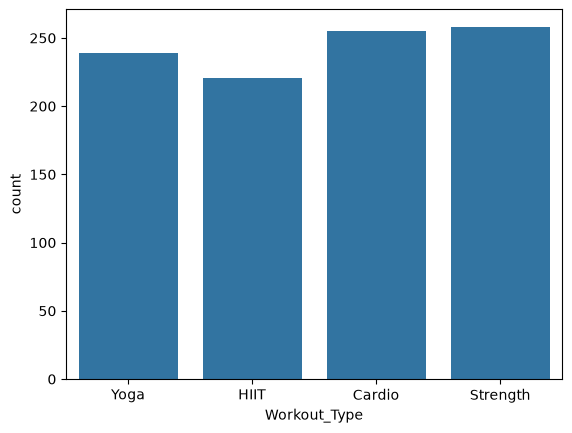

In [162]:
df["Workout_Type"].value_counts(normalize=True)
sb.countplot(data=df, x="Workout_Type")

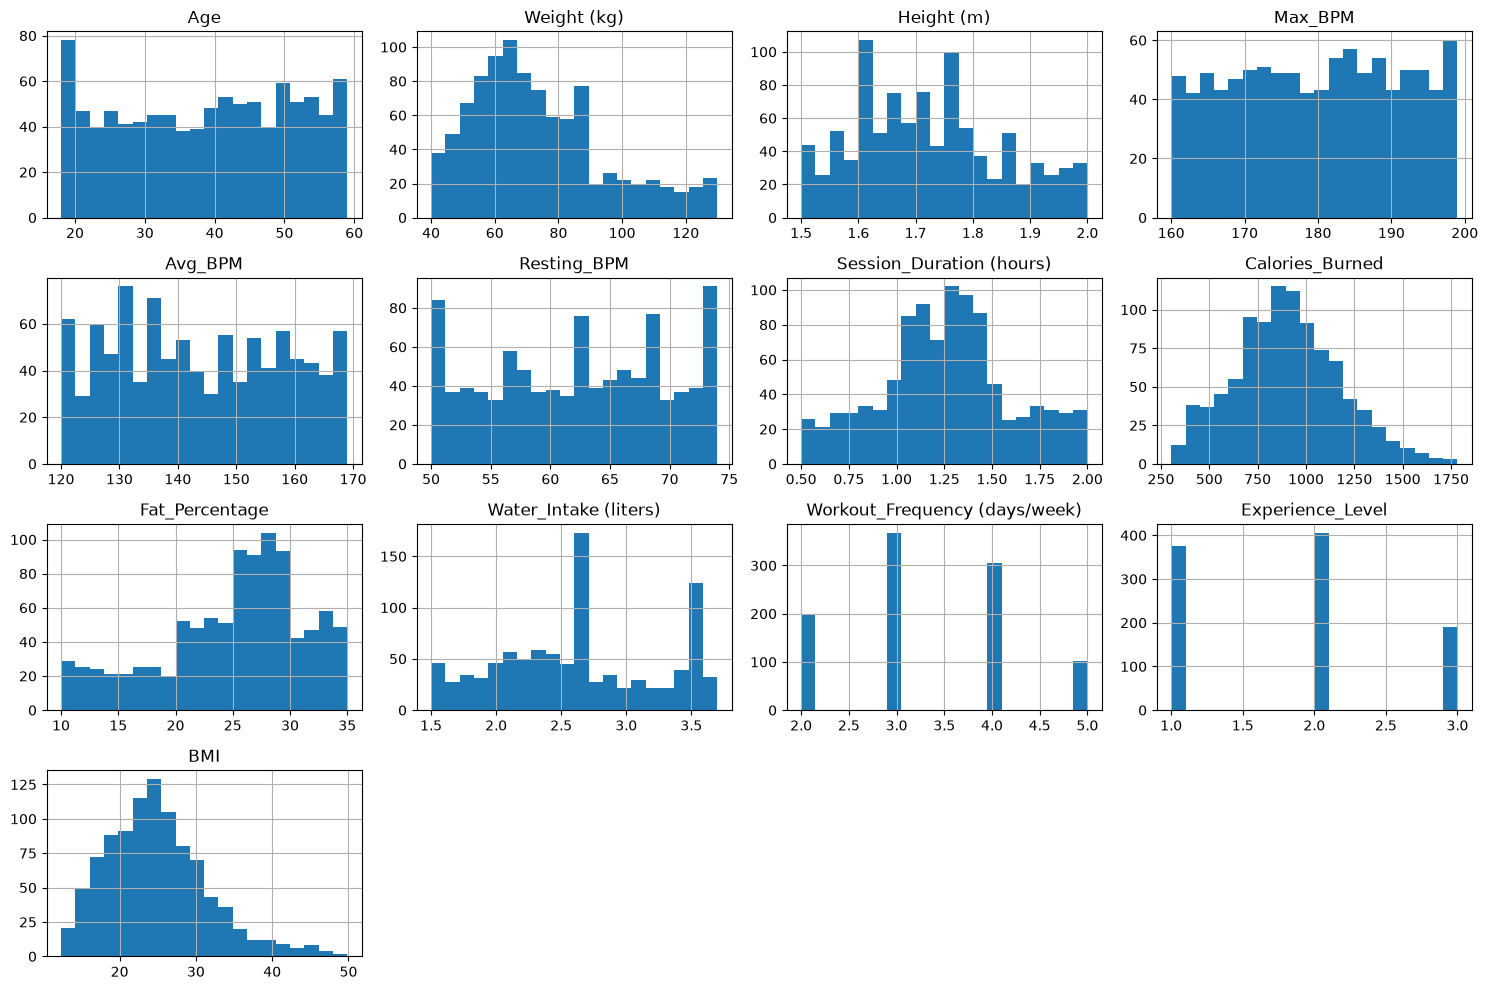

In [163]:
cols = df.select_dtypes(include="number").columns
df[cols].hist(bins=20, figsize=(15, 10))
plt.tight_layout()
plt.show()

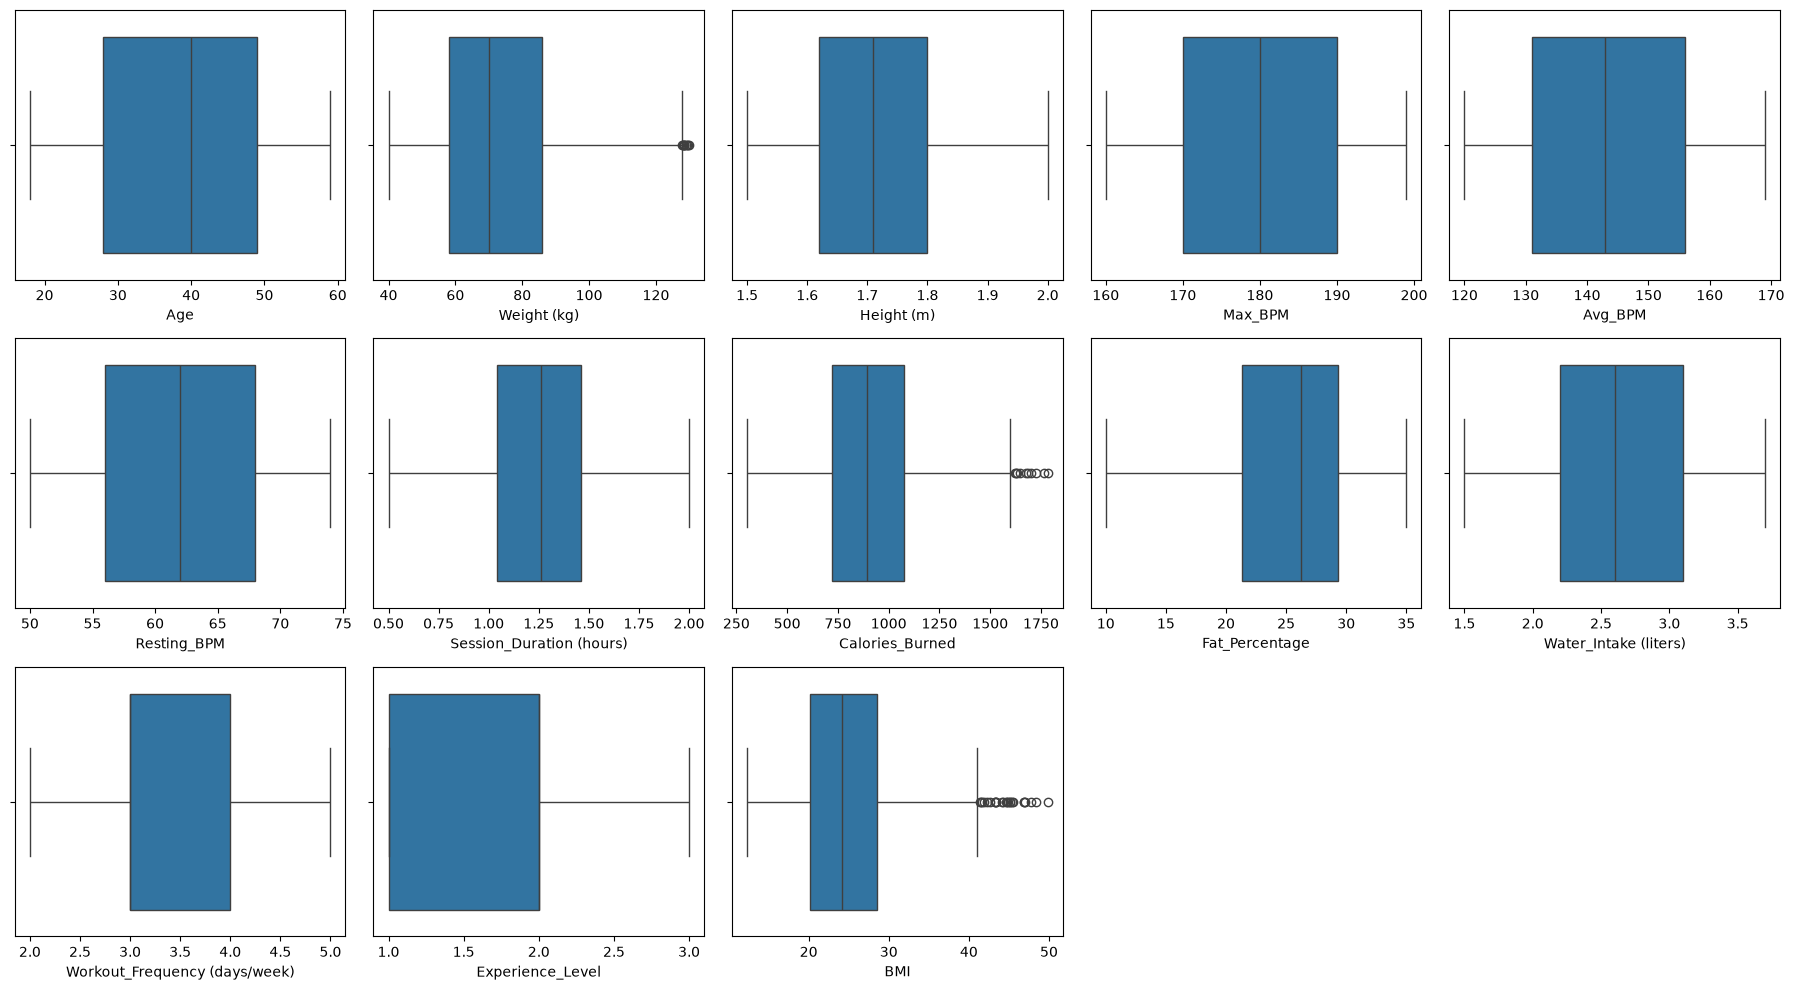

In [164]:
fig, axes = plt.subplots(3, 5, figsize=(18, 10))
axes = axes.flatten()
for i, col in enumerate(cols):
    sb.boxplot(x=df[col], ax=axes[i])
for j in range(len(cols), len(axes)):
    axes[j].set_visible(False)
plt.tight_layout()
plt.show()

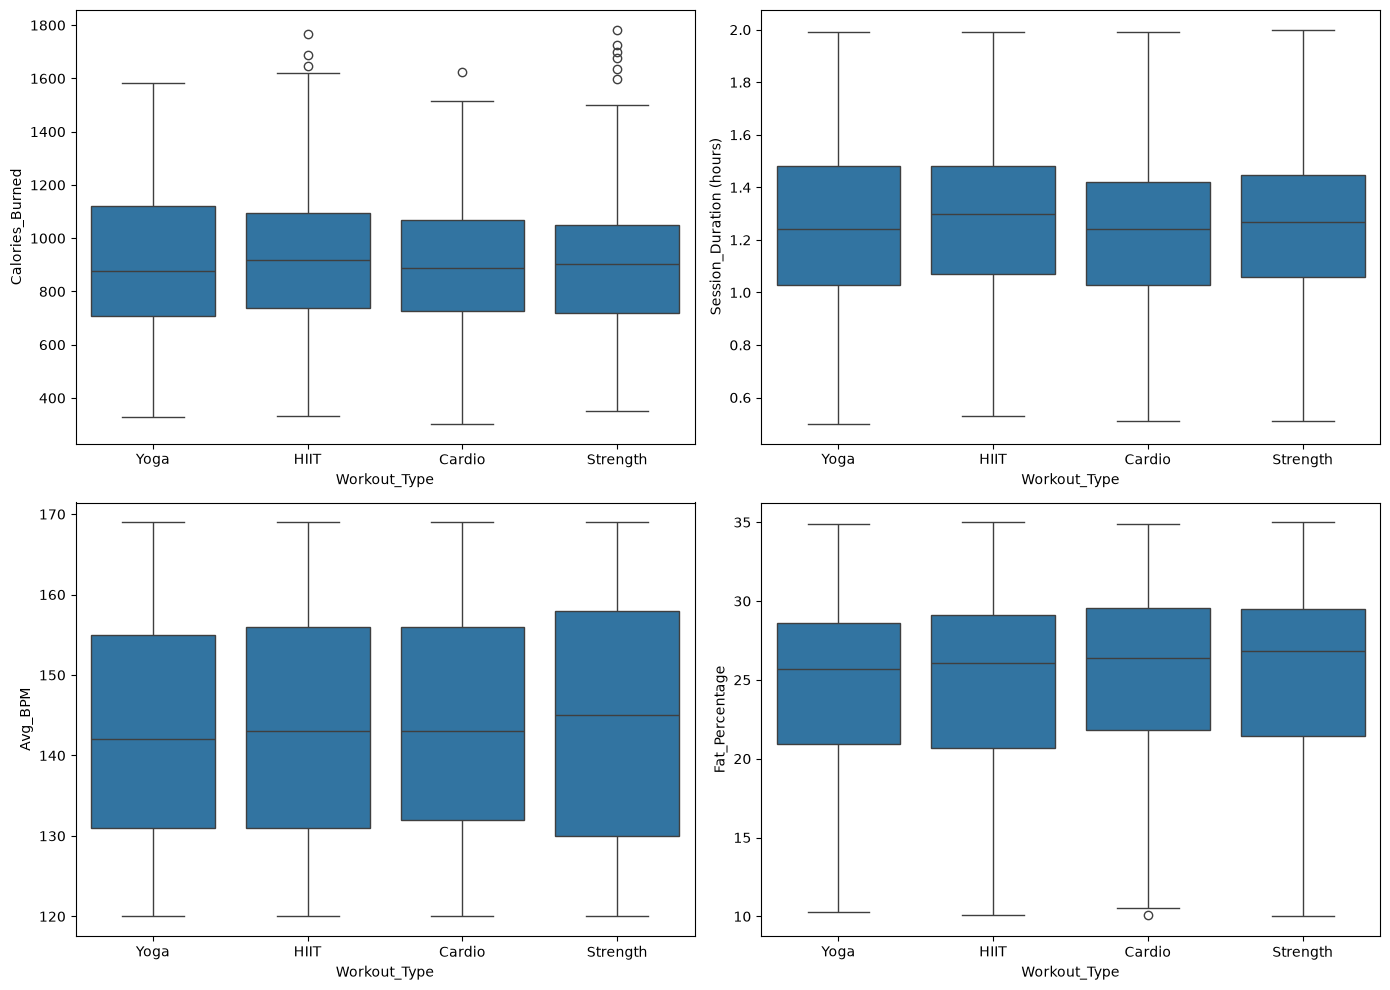

In [165]:
features = ["Calories_Burned", "Session_Duration (hours)", "Avg_BPM", "Fat_Percentage"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for i, col in enumerate(features):
    sb.boxplot(data=df, x="Workout_Type", y=col, ax=axes[i])
plt.tight_layout()
plt.show()

<Axes: xlabel='Workout_Type', ylabel='count'>

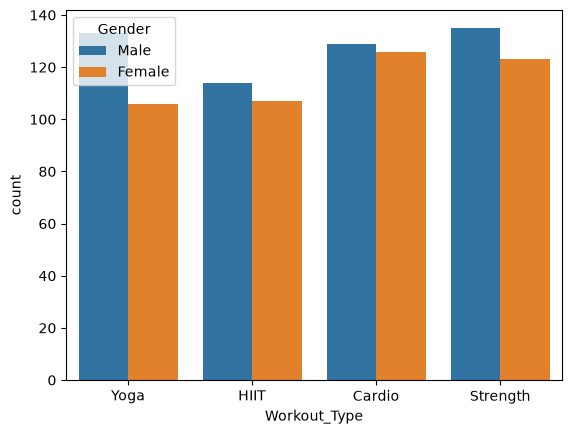

In [166]:
sb.countplot(data=df, x="Workout_Type", hue="Gender")

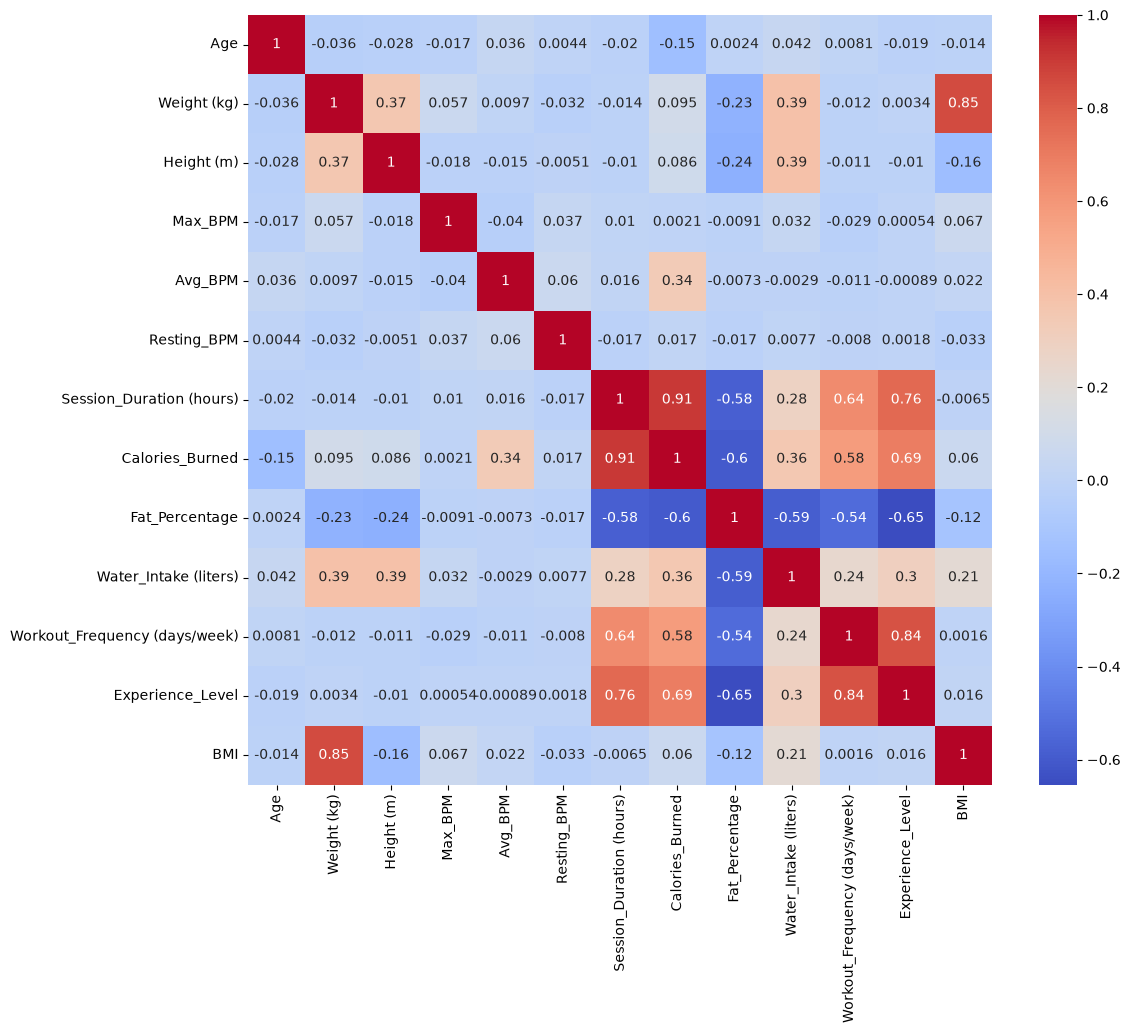

In [167]:
plt.figure(figsize=(12, 10))
sb.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.show()

In [168]:
X = df.drop(columns="Workout_Type")
y = df["Workout_Type"]
X = pd.get_dummies(X, columns=["Gender"], drop_first=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [169]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Test:", accuracy_score(y_test, y_pred))
print("Train:", model.score(X_train, y_train))
print(classification_report(y_test, y_pred))

Test: 0.26153846153846155
Train: 1.0
              precision    recall  f1-score   support

      Cardio       0.25      0.25      0.25        51
        HIIT       0.23      0.27      0.25        44
    Strength       0.30      0.33      0.31        52
        Yoga       0.27      0.19      0.22        48

    accuracy                           0.26       195
   macro avg       0.26      0.26      0.26       195
weighted avg       0.26      0.26      0.26       195



In [170]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
 "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "min_samples_split": [2, 5, 10, 20, 40],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "max_features": [None, "sqrt", "log2"],
    "ccp_alpha": [0.0, 0.001, 0.005, 0.01],
    "class_weight": [None, "balanced"],
}
grid = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_distributions=param_grid,
    n_iter=300,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)
grid.fit(X_train, y_train)
best_model = grid.best_estimator_
print(grid.best_params_)
print(grid.best_score_)
y_pred_grid = grid.best_estimator_.predict(X_test)
print(accuracy_score(y_test, y_pred_grid))
print(classification_report(y_test, y_pred_grid))

{'min_samples_split': 2, 'min_samples_leaf': 10, 'max_features': 'log2', 'max_depth': 6, 'criterion': 'entropy', 'class_weight': 'balanced', 'ccp_alpha': 0.0}
0.28028122415219187
0.23076923076923078
              precision    recall  f1-score   support

      Cardio       0.23      0.06      0.09        51
        HIIT       0.21      0.34      0.26        44
    Strength       0.27      0.33      0.30        52
        Yoga       0.22      0.21      0.21        48

    accuracy                           0.23       195
   macro avg       0.23      0.23      0.21       195
weighted avg       0.23      0.23      0.21       195



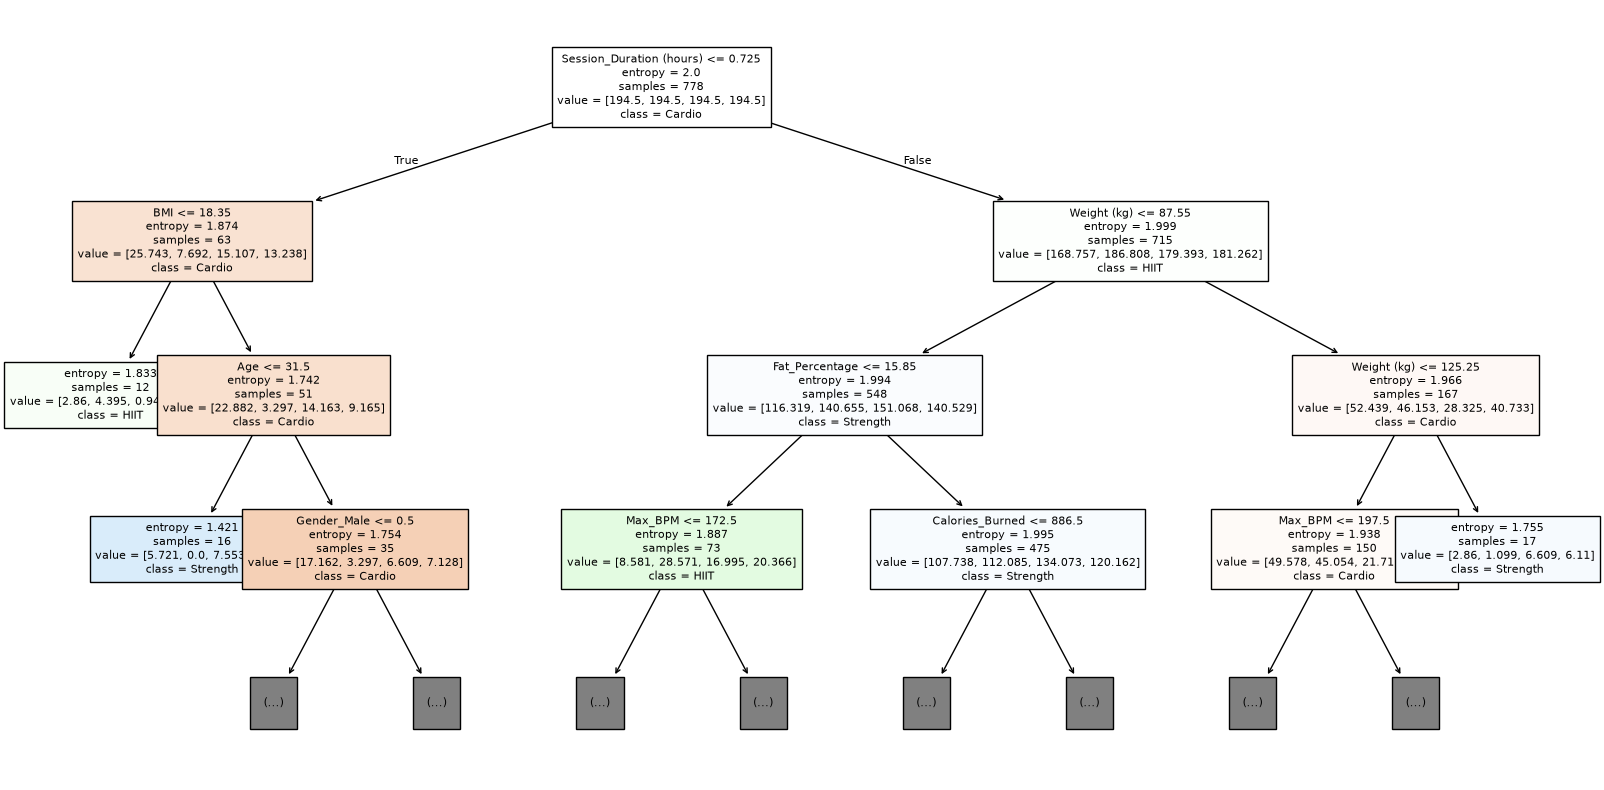

In [171]:
plt.figure(figsize=(20, 10))
plot_tree(
    best_model,
    max_depth=3,
    feature_names=X_train.columns,
    class_names=best_model.classes_,
    filled=True,
    fontsize=8,
)
plt.show()